
# Don't Get Kicked — прогнозирование неудачных покупок автомобилей

**Задача:** построение модели бинарной классификации для прогнозирования вероятности неудачной покупки подержанного автомобиля (`IsBadBuy`).

В проекте рассматриваются этапы исследования данных, подготовки признаков, обучения моделей машинного обучения и оценки качества классификации.


## 0. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



# 1. Initial Data Audit

In [2]:
data = pd.read_csv(
    '../data/training.csv'
)

data.shape

(72983, 34)

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 72983 entries, 0 to 72982
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   RefId                              72983 non-null  int64  
 1   IsBadBuy                           72983 non-null  int64  
 2   PurchDate                          72983 non-null  str    
 3   Auction                            72983 non-null  str    
 4   VehYear                            72983 non-null  int64  
 5   VehicleAge                         72983 non-null  int64  
 6   Make                               72983 non-null  str    
 7   Model                              72983 non-null  str    
 8   Trim                               70623 non-null  str    
 9   SubModel                           72975 non-null  str    
 10  Color                              72975 non-null  str    
 11  Transmission                       72974 non-null  str    
 12  W

In [5]:
display(data.head())

,RefId,IsBadBuy,PurchDate,Auction,VehYear,VehicleAge,Make,Model,Trim,SubModel,Color,Transmission,WheelTypeID,WheelType,VehOdo,Nationality,Size,TopThreeAmericanName,MMRAcquisitionAuctionAveragePrice,MMRAcquisitionAuctionCleanPrice,MMRAcquisitionRetailAveragePrice,MMRAcquisitonRetailCleanPrice,MMRCurrentAuctionAveragePrice,MMRCurrentAuctionCleanPrice,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART,BYRNO,VNZIP1,VNST,VehBCost,IsOnlineSale,WarrantyCost
0,1,0,12/7/2009,ADESA,2006,3,MAZDA,MAZDA3,i,4D SEDAN I,RED,AUTO,1.0,Alloy,89046,OTHER ASIAN,MEDIUM,OTHER,8155.0,9829.0,11636.0,13600.0,7451.0,8552.0,11597.0,12409.0,NaN,NaN,21973,33619,FL,7100.0,0,1113
1,2,0,12/7/2009,ADESA,2004,5,DODGE,1500 RAM PICKUP 2WD,ST,QUAD CAB 4.7L SLT,WHITE,AUTO,1.0,Alloy,93593,AMERICAN,LARGE TRUCK,CHRYSLER,6854.0,8383.0,10897.0,12572.0,7456.0,9222.0,11374.0,12791.0,NaN,NaN,19638,33619,FL,7600.0,0,1053
2,3,0,12/7/2009,ADESA,2005,4,DODGE,STRATUS V6,SXT,4D SEDAN SXT FFV,MAROON,AUTO,2.0,Covers,73807,AMERICAN,MEDIUM,CHRYSLER,3202.0,4760.0,6943.0,8457.0,4035.0,5557.0,7146.0,8702.0,NaN,NaN,19638,33619,FL,4900.0,0,1389
3,4,0,12/7/2009,ADESA,2004,5,DODGE,NEON,SXT,4D SEDAN,SILVER,AUTO,1.0,Alloy,65617,AMERICAN,COMPACT,CHRYSLER,1893.0,2675.0,4658.0,5690.0,1844.0,2646.0,4375.0,5518.0,NaN,NaN,19638,33619,FL,4100.0,0,630
4,5,0,12/7/2009,ADESA,2005,4,FORD,FOCUS,ZX3,2D COUPE ZX3,SILVER,MANUAL,2.0,Covers,69367,AMERICAN,COMPACT,FORD,3913.0,5054.0,7723.0,8707.0,3247.0,4384.0,6739.0,7911.0,NaN,NaN,19638,33619,FL,4000.0,0,1020


In [6]:
missing = data.isnull().sum()
missing[missing>0].sort_values(ascending=False)

AUCGUART                             69564
PRIMEUNIT                            69564
WheelType                             3174
WheelTypeID                           3169
Trim                                  2360
MMRCurrentAuctionAveragePrice          315
MMRCurrentAuctionCleanPrice            315
MMRCurrentRetailAveragePrice           315
MMRCurrentRetailCleanPrice             315
MMRAcquisitionAuctionCleanPrice         18
MMRAcquisitionAuctionAveragePrice       18
MMRAcquisitionRetailAveragePrice        18
MMRAcquisitonRetailCleanPrice           18
Transmission                             9
SubModel                                 8
Color                                    8
Size                                     5
Nationality                              5
TopThreeAmericanName                     5
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(0)

In [8]:
print(data["IsBadBuy"].value_counts(), data["IsBadBuy"].value_counts(normalize=True) * 100)

IsBadBuy
0    64007
1     8976
Name: count, dtype: int64 IsBadBuy
0    87.701245
1    12.298755
Name: proportion, dtype: float64


In [9]:
print(data["PurchDate"].nunique(), '\n', data["PurchDate"].head())

517 
 0    12/7/2009
1    12/7/2009
2    12/7/2009
3    12/7/2009
4    12/7/2009
Name: PurchDate, dtype: str


In [10]:
data['PurchDate'] = pd.to_datetime(data['PurchDate'], format="%m/%d/%Y")
data['PurchDate'].dtype


dtype('<M8[us]')

In [11]:
data["PurchDate"].min(), data["PurchDate"].max()

(Timestamp('2009-01-05 00:00:00'), Timestamp('2010-12-30 00:00:00'))

### 1.1. Общая информация о датасете

На начальном этапе проведён первичный осмотр данных: изучены размерность датасета, типы признаков, пропущенные значения и структура целевой переменной.

Основные характеристики:

| Параметр | Значение |
|---|---:|
| Количество наблюдений | 72 983 |
| Количество столбцов | 34 |
| Целевая переменная | `IsBadBuy` |
| Тип задачи | Бинарная классификация |
| Уникальных дат покупки | 517 |
| Период наблюдений | 05.01.2009 – 30.12.2010 |
| Полных дубликатов | 0 |

Целевая переменная `IsBadBuy` принимает два значения:
- `0` — покупка не классифицируется как неудачная;
- `1` — неудачная покупка.

### 1.2. Анализ пропущенных значений

Пропуски обнаружены в 19 признаках. Наибольшая их концентрация приходится на `AUCGUART` и `PRIMEUNIT`.

| Признак | Пропуски | Доля, % |
|---|---:|---:|
| `AUCGUART` | 69 564 | 95.3 |
| `PRIMEUNIT` | 69 564 | 95.3 |
| `WheelType` | 3 174 | 4.3 |
| `WheelTypeID` | 3 169 | 4.3 |
| `Trim` | 2 360 | 3.2 |
| `MMRCurrent*` (4 признака) | 315 | 0.4 |
| `MMRAcquisition*` (4 признака) | 18 | 0.02 |
| `Transmission` | 9 | 0.01 |
| `SubModel`, `Color` | 8 | 0.01 |
| `Size`, `Nationality`, `TopThreeAmericanName` | 5 | 0.01 |

Большая доля пропусков в `AUCGUART` и `PRIMEUNIT` требует отдельного рассмотрения. Автоматическое удаление этих признаков на данном этапе не выполняется: отсутствие значения потенциально может нести информацию.

Для остальных признаков с пропусками стратегия обработки будет определена на этапе предобработки.

### 1.3. Распределение целевой переменной

Распределение классов:

| Класс | Количество | Доля, % |
|---|---:|---:|
| 0 | 64 007 | 87.70 |
| 1 | 8 976 | 12.30 |

В датасете наблюдается выраженный дисбаланс классов: доля неудачных покупок составляет около 12.3%.

Это необходимо учитывать при обучении и оценке моделей. Accuracy в данном случае может давать завышенное представление о качестве классификатора, поэтому основное внимание будет уделено метрикам Gini и AUC PR, а также Precision, Recall и F1.

### 1.4. Подготовка временного признака

Признак `PurchDate` содержит дату покупки автомобиля. Исходный тип данных — строковый. Он преобразован в формат `datetime` для дальнейшей работы с хронологией наблюдений.

Диапазон дат: с 5 января 2009 года по 30 декабря 2010 года. Всего в датасете 517 уникальных дат.

**Особенность дальнейшего исследования:** разделение на обучающую, валидационную и тестовую выборки будет выполнено по времени, а не случайным образом. Это позволит сохранить хронологический порядок наблюдений и избежать использования будущих данных при обучении модели.

### 1.5. Промежуточные выводы

По результатам первичного аудита установлено:

1. Датасет содержит 72 983 наблюдения и 34 столбца.
2. Полные дубликаты отсутствуют.
3. В целевой переменной наблюдается дисбаланс классов.
4. В двух признаках доля пропусков превышает 95%.
5. Данные имеют временную структуру, которую необходимо учитывать при формировании выборок.

На следующем этапе будет выполнено хронологическое разделение данных на Train, Validation и Test. После разделения исследовательский анализ и настройка предобработки будут проводиться с учётом недопустимости утечки данных.



# 2. Temporal Data Split

Для оценки способности модели обобщать закономерности на будущие наблюдения используется хронологическое разделение данных.

Вместо случайного разделения по строкам используются уникальные даты покупки (`PurchDate`). Это позволяет сохранить целостность временных периодов: все наблюдения, относящиеся к одной дате, попадают в одну выборку.

Такой подход исключает ситуацию, при которой данные об автомобилях, приобретённых в один день, одновременно оказываются в обучающей и валидационной выборках.

Порядок разделения:
- **Train** — первые ⅓ дат;
- **Validation** — следующие ⅓ дат;
- **Test** — последние ⅓ дат.

Таким образом, модель обучается на наиболее ранних наблюдениях, подбирается на более поздних и окончательно оценивается на самом позднем временном периоде.


In [12]:
dates = sorted(data["PurchDate"].unique())

n = len(dates)
train_end = n // 3
valid_end = 2 * n // 3

train_dates = dates[:train_end]
valid_dates = dates[train_end:valid_end]
test_dates = dates[valid_end:]

In [13]:
for name, period in [
    ("Train", train_dates),
    ("Validation", valid_dates),
    ("Test", test_dates)
]:
    print(f"{name}: {len(period)} dates | {period[0]} - {period[-1]}")

Train: 172 dates | 2009-01-05 00:00:00 - 2009-09-01 00:00:00
Validation: 172 dates | 2009-09-02 00:00:00 - 2010-04-30 00:00:00
Test: 173 dates | 2010-05-03 00:00:00 - 2010-12-30 00:00:00


In [14]:
train = data[data["PurchDate"].isin(train_dates)].copy()
valid = data[data["PurchDate"].isin(valid_dates)].copy()
test = data[data["PurchDate"].isin(test_dates)].copy()

for name, sample in [
    ("Train", train),
    ("Validation", valid),
    ("Test", test)
]:
    print(f"{name}: {sample.shape[0]:,} rows")

Train: 23,059 rows
Validation: 24,104 rows
Test: 25,820 rows


In [15]:
assert len(train) + len(valid) + len(test) == len(data)

assert train["PurchDate"].max() < valid["PurchDate"].min()
assert valid["PurchDate"].max() < test["PurchDate"].min()

print("Split completed successfully!")

Split completed successfully!



### 2.1. Результаты временного разделения

В результате хронологического разделения сформированы три выборки:

| Выборка | Количество строк | Доля данных | Временной диапазон |
|---|---:|---:|---|
| Train | 23 059 | 31.6% | 05.01.2009 – 01.09.2009 |
| Validation | 24 104 | 33.0% | 02.09.2009 – 30.04.2010 |
| Test | 25 820 | 35.4% | 03.05.2010 – 30.12.2010 |
| **Всего** | **72 983** | **100%** | — |

Проверки подтвердили:
- все наблюдения распределены между тремя выборками;
- временные периоды не пересекаются;
- хронологический порядок соблюдён.

Обучающая выборка будет использоваться для исследования данных и обучения моделей, Validation — для выбора и настройки моделей, Test — исключительно для финальной оценки качества.


# 3. Exploratory Data Analysis (EDA)

### 3.1. Распределение целевой переменной

In [16]:
print(train["IsBadBuy"].value_counts(), train["IsBadBuy"].value_counts(normalize=True) * 100)

IsBadBuy
0    20452
1     2607
Name: count, dtype: int64 IsBadBuy
0    88.694219
1    11.305781
Name: proportion, dtype: float64


В обучающей выборке наблюдается выраженный дисбаланс классов:

| Класс | Количество | Доля, % |
|---|---:|---:|
| 0 — GoodBuy | 20 452 | 88.69 |
| 1 — BadBuy | 2 607 | 11.31 |
| **Всего** | **23 059** | **100.00** |

Доля неудачных покупок в обучающей выборке составляет 11.31%, что немного ниже показателя по всему датасету (12.30%).

Дисбаланс классов необходимо учитывать при обучении моделей и выборе метрик качества. В частности, высокая Accuracy сама по себе не будет свидетельствовать о способности модели выявлять неудачные покупки.


### 3.2. Описательная статистика числовых признаков

In [17]:
train.describe().T

,count,mean,min,25%,50%,75%,max,std
RefId,23059.0,37370.633289,427.0,19343.5,37297.0,56375.5,72830.0,20948.02459
IsBadBuy,23059.0,0.113058,0.0,0.0,0.0,0.0,1.0,0.31667
PurchDate,23059,2009-05-04 01:14:03.835378,2009-01-05 00:00:00,2009-03-02 00:00:00,2009-04-29 00:00:00,2009-07-07 00:00:00,2009-09-01 00:00:00,NaN
VehYear,23059.0,2004.814389,2001.0,2004.0,2005.0,2006.0,2008.0,1.597221
VehicleAge,23059.0,4.185654,1.0,3.0,4.0,5.0,8.0,1.597284
WheelTypeID,22187.0,1.473205,1.0,1.0,1.0,2.0,3.0,0.518947
VehOdo,23059.0,69737.075155,5368.0,60318.5,71555.0,80396.5,107091.0,14295.517643
MMRAcquisitionAuctionAveragePrice,23058.0,5781.616792,0.0,3940.25,5500.0,7462.0,33543.0,2486.934071
MMRAcquisitionAuctionCleanPrice,23058.0,7008.196808,0.0,4989.0,6616.0,8740.0,36701.0,2775.864575
MMRAcquisitionRetailAveragePrice,23058.0,6737.105213,0.0,4756.25,6440.0,8559.0,36726.0,2703.002237


Для изучения числовых признаков рассчитаны основные статистические характеристики: среднее значение, стандартное отклонение, минимум, максимум и квартили.

По результатам анализа можно отметить несколько особенностей:

- **Различные масштабы признаков.** Например, медиана пробега (`VehOdo`) составляет 71 555, стоимости автомобиля (`VehBCost`) — 6 190, стоимости гарантии (`WarrantyCost`) — 1 215. Различия в масштабах необходимо учитывать при подготовке данных для алгоритмов Logistic Regression и KNN.

- **Потенциальные выбросы.** В некоторых признаках максимальные значения существенно превышают медианные. Например, максимальная стоимость автомобиля (`VehBCost`) составляет 45 469 при медиане 6 190. Эти наблюдения требуют дополнительного исследования.

- **Особенности числового представления.** Некоторые признаки, например `RefId`, `BYRNO`, `VNZIP1` и `WheelTypeID`, представлены числами, но имеют идентификационную или категориальную природу. Их нельзя автоматически интерпретировать как количественные переменные.

- **Наличие пропусков.** В ценовых признаках MMR количество наблюдений меньше общего размера обучающей выборки. Стратегия обработки пропусков будет определена на этапе предобработки.

На данном этапе преобразования и удаление потенциальных выбросов не выполняются. Для более детального исследования распределений признаков будут использованы графические методы анализа.


### 3.3. Анализ уникальных значений признаков

In [18]:
train.nunique(dropna=False).sort_values()

IsOnlineSale                             1
IsBadBuy                                 2
AUCGUART                                 2
PRIMEUNIT                                2
Transmission                             3
Auction                                  3
WheelTypeID                              4
WheelType                                4
TopThreeAmericanName                     4
Nationality                              4
VehYear                                  8
VehicleAge                               8
Size                                    12
Color                                   17
VNST                                    29
Make                                    31
BYRNO                                   35
VNZIP1                                 111
Trim                                   123
PurchDate                              172
WarrantyCost                           238
SubModel                               651
Model                                  795
VehBCost   

Для оценки вариативности признаков было рассчитано количество уникальных значений в каждом столбце обучающей выборки.

По результатам анализа выявлены следующие особенности:

- `IsOnlineSale` содержит только одно уникальное значение и является константным признаком.
- `RefId` имеет уникальное значение для каждой строки и представляет собой идентификатор наблюдения.
- `BYRNO` и `VNZIP1` содержат ограниченное количество уникальных значений и требуют отдельного рассмотрения.
- Ряд признаков, представленных числовыми кодами, фактически являются категориальными (`WheelTypeID`).

Константный признак `IsOnlineSale` не содержит вариативности и не несёт информации для разделения наблюдений. Его исключение будет учтено на этапе подготовки признаков.

Идентификаторы и категориальные признаки будут рассмотрены отдельно перед обучением моделей.


### 3.4. Анализ распределений числовых признаков

Для изучения формы распределений и выявления возможной асимметрии используем гистограммы. На первом этапе рассмотрим распределения признаков, которые описывают характеристики автомобиля:

- `VehOdo` — пробег;
- `VehBCost` — стоимость приобретения автомобиля;
- `WarrantyCost` — стоимость гарантии;
- `VehicleAge` — возраст автомобиля.

Это понятные количественные характеристики, которые потенциально могут быть связаны с вероятностью неудачной покупки.


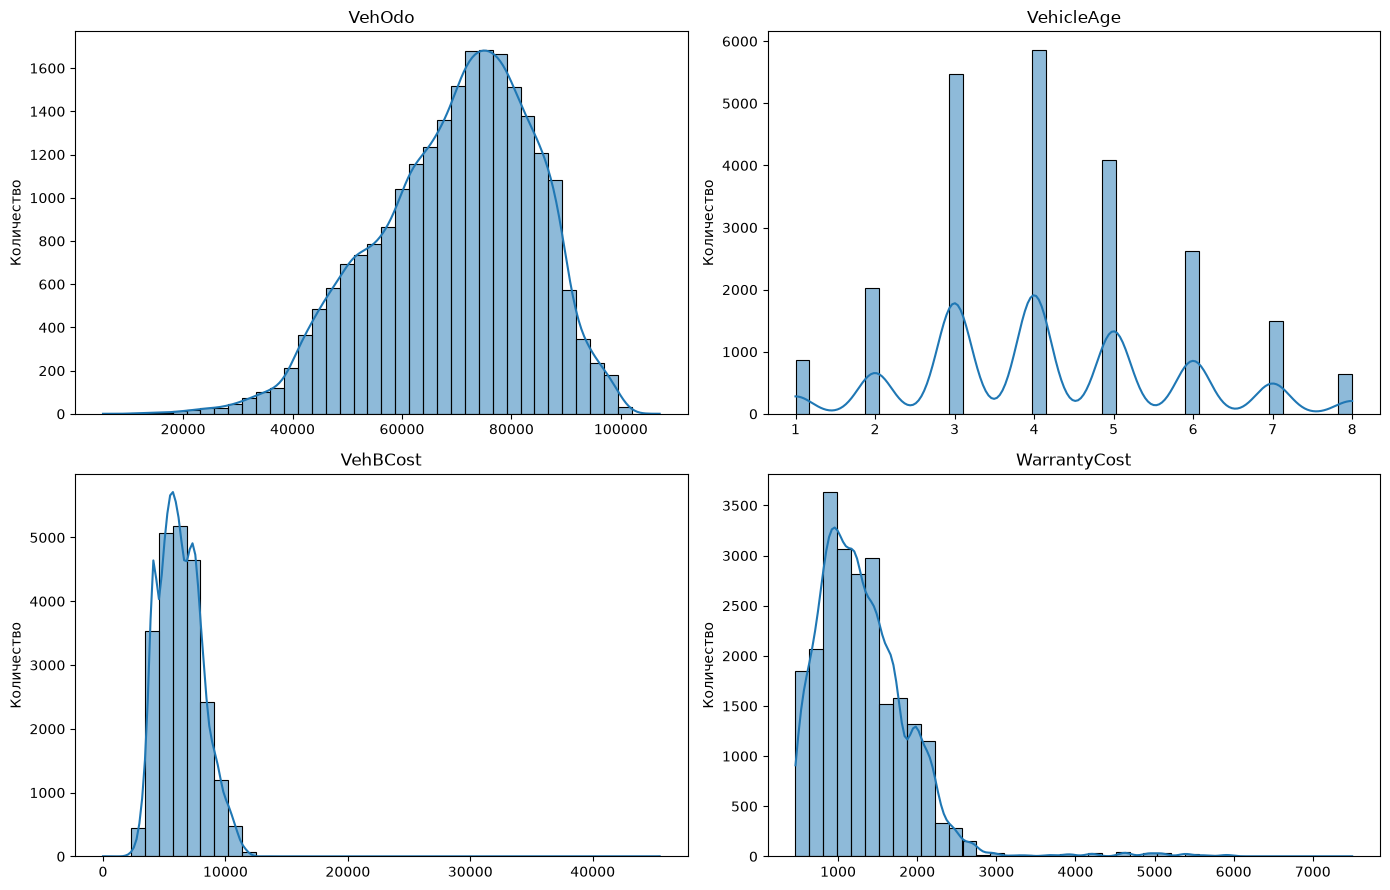

In [19]:
num_features = [
    "VehOdo",
    "VehicleAge",
    "VehBCost",
    "WarrantyCost"
]

fig, axes = plt.subplots(2,2, figsize =(14,9))

for feature, ax in zip(num_features, axes.flat):
    sns.histplot(data=train, x=feature, bins=40, kde=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Количество")

plt.tight_layout()
plt.show()

Для изучения распределений числовых признаков построены гистограммы с оценкой плотности распределения (KDE).

**Основные наблюдения:**

- `VehOdo` — унимодальное распределение с правосторонней асимметрией. Основная масса автомобилей сосредоточена в среднем диапазоне пробега, при этом наблюдается длинный хвост больших значений.
- `VehicleAge` — дискретный признак со значениями от 1 до 8 лет. Наиболее высокая частота наблюдается у автомобилей среднего возраста.
- `VehBCost` — выраженная правосторонняя асимметрия. Большинство значений сосредоточено в относительно узком диапазоне, при этом присутствуют редкие наблюдения с высокой стоимостью.
- `WarrantyCost` — сильная правосторонняя асимметрия. Основная масса значений находится в нижней части диапазона, распределение имеет длинный правый хвост.

**Выводы:**

1. `VehBCost` и `WarrantyCost` имеют выраженную асимметрию и потенциальные выбросы. В дальнейшем можно проверить влияние логарифмирования и ограничения экстремальных значений на качество моделей.
2. `VehicleAge` является дискретным порядковым признаком. На первом этапе оставим его числовым.
3. Числовые признаки имеют разные масштабы. Перед обучением логистической регрессии и KNN потребуется масштабирование.
4. На данном этапе выбросы не удаляются, а исходные значения признаков сохраняются для дальнейшего сравнения моделей.


### 3.5. Анализ категориальных признаков

На данном этапе исследуются категориальные признаки обучающей выборки. Цель анализа — определить количество уникальных категорий, оценить кардинальность признаков и выявить особенности их распределения.

In [20]:
categorical_features = train.select_dtypes(
    include=['object', 'category', 'str']
).columns.tolist()

for feature in categorical_features:
    print(
        f"{feature}: "
        f"{train[feature].nunique()} уникальных значений"
    )

Auction: 3 уникальных значений
Make: 31 уникальных значений
Model: 795 уникальных значений
Trim: 122 уникальных значений
SubModel: 650 уникальных значений
Color: 16 уникальных значений
Transmission: 2 уникальных значений
WheelType: 3 уникальных значений
Nationality: 4 уникальных значений
Size: 12 уникальных значений
TopThreeAmericanName: 4 уникальных значений
PRIMEUNIT: 1 уникальных значений
AUCGUART: 1 уникальных значений
VNST: 29 уникальных значений



### 3.5.1 Количество уникальных значений

Для каждого категориального признака рассчитано количество уникальных значений без учёта пропусков.

Результаты показывают, что признаки существенно различаются по кардинальности:

- Низкая кардинальность: `Auction`, `Transmission`, `WheelType`, `Nationality`, `Color`, `Size`, `TopThreeAmericanName`.
- Высокая кардинальность: `Model`, `SubModel`, `Trim`.
- Умеренная кардинальность: `Make`, `VNST`.

Особого внимания требуют `Model`, `SubModel` и `Trim`, поскольку большое количество уникальных категорий может существенно увеличить размерность данных при One-Hot Encoding.

Признаки `PRIMEUNIT` и `AUCGUART` имеют по одному уникальному непустому значению. С учётом большого количества пропусков их информативность необходимо оценить дополнительно.

Полученные результаты будут учитываться при выборе способа кодирования категориальных признаков.


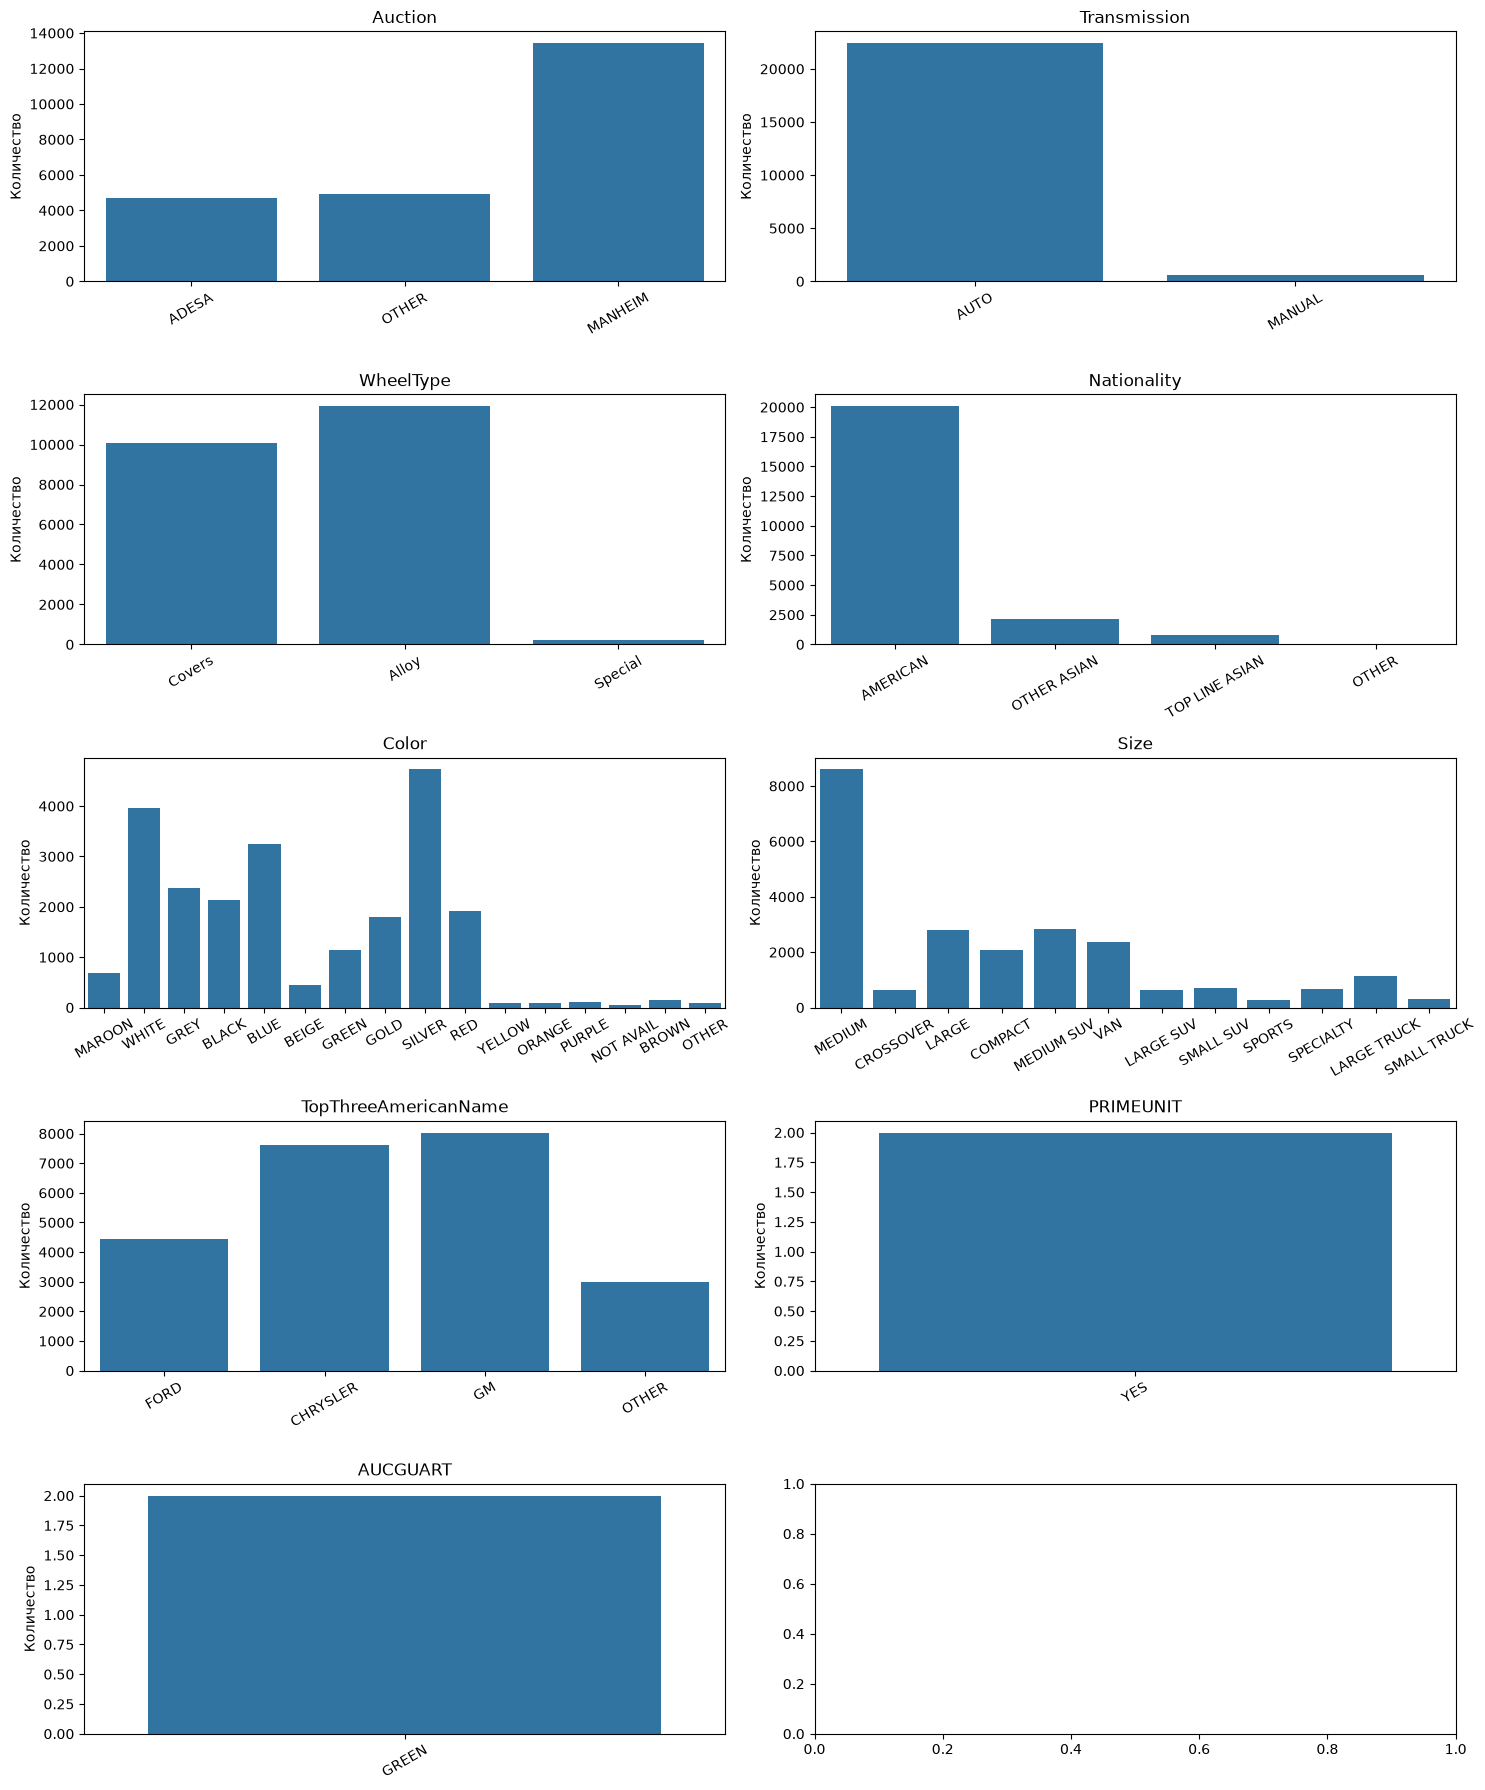

In [21]:
low_cardinality = [
    "Auction",
    "Transmission",
    "WheelType",
    "Nationality",
    "Color",
    "Size",
    "TopThreeAmericanName",
    "PRIMEUNIT",
    "AUCGUART"
]

fig, axes = plt.subplots(5, 2, figsize=(15, 18))

for feature, ax in zip(low_cardinality, axes.flat):
    sns.countplot(data=train, x=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


**Выводы:**

1. Большинство категориальных признаков имеют несбалансированное распределение.
2. Некоторые категории встречаются значительно реже остальных. Это необходимо учитывать при кодировании признаков и обучении моделей.
3. `PRIMEUNIT` и `AUCGUART` содержат слишком мало непустых значений для полноценного анализа. Их информативность и целесообразность использования необходимо оценить отдельно.
4. На данном этапе категории не объединяются и не удаляются.

### 3.6. Анализ взаимосвязи признаков с целевой переменной

Для выявления потенциально значимых закономерностей исследуем зависимость целевой переменной `IsBadBuy` от характеристик автомобилей.

Поскольку `IsBadBuy` является бинарной переменной (0 — успешная покупка, 1 — неудачная покупка), среднее значение этого признака внутри каждой категории соответствует доле неудачных покупок.

На первом этапе рассмотрим категориальные признаки с небольшим количеством уникальных значений.


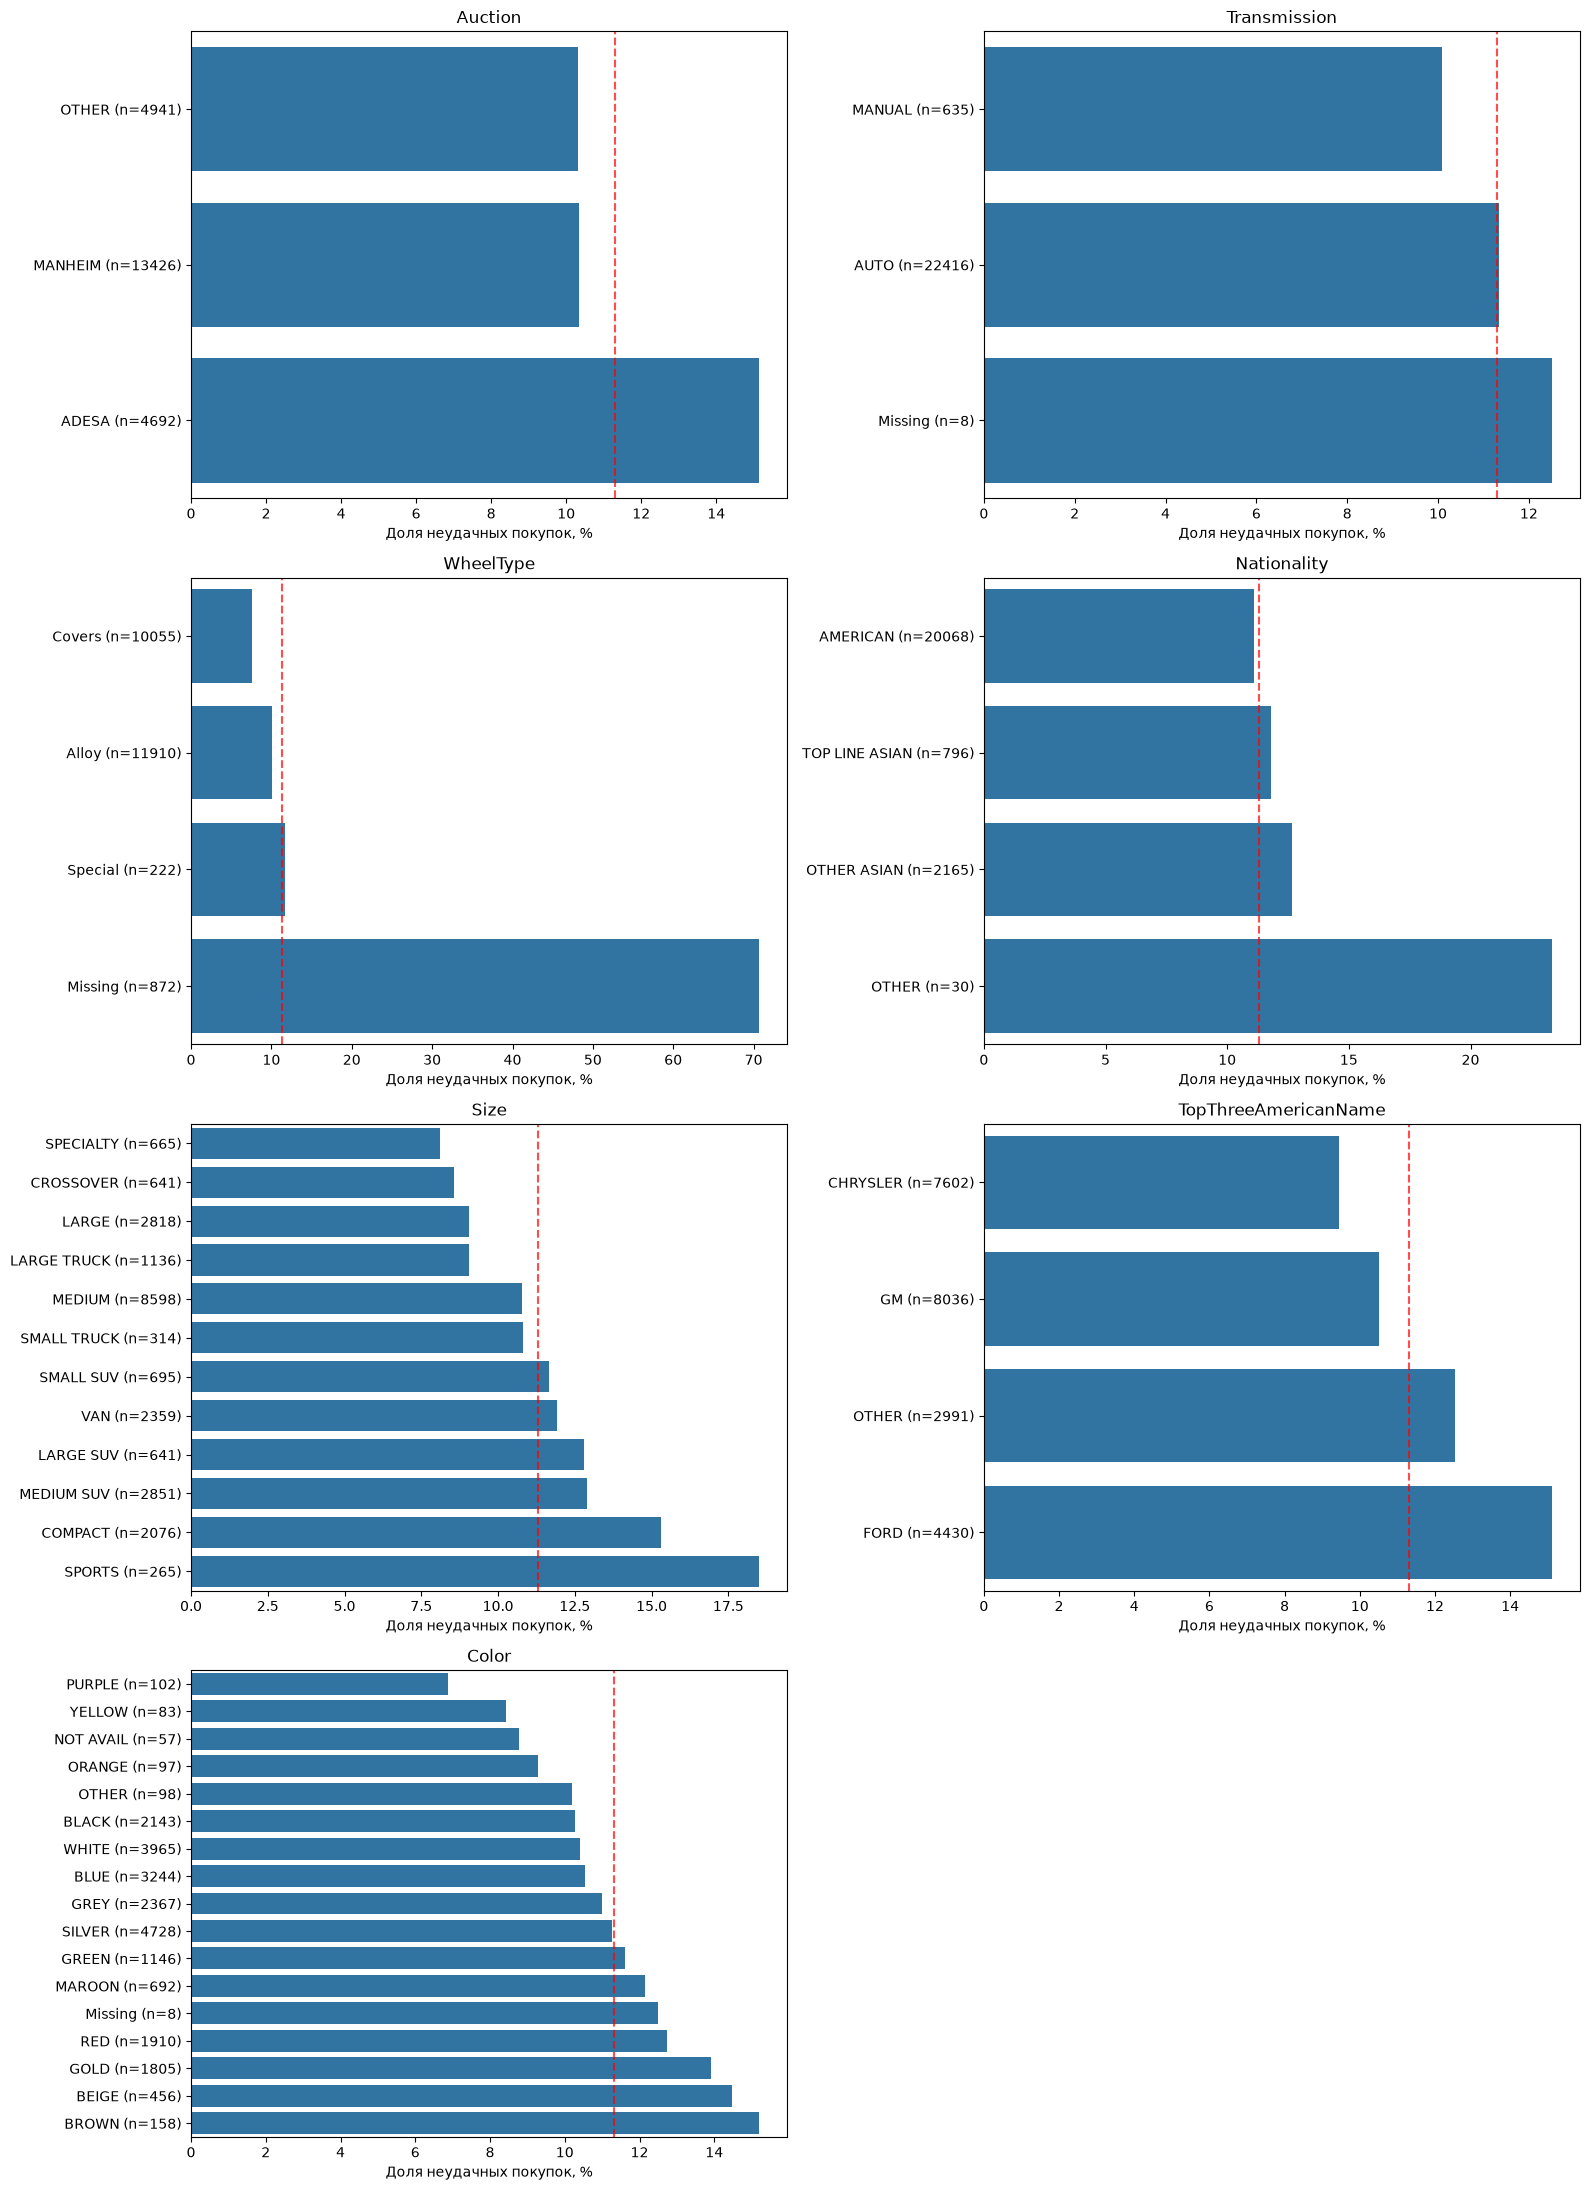

In [22]:

categorical_features = [
    "Auction",
    "Transmission",
    "WheelType",
    "Nationality",
    "Size",
    "TopThreeAmericanName",
    "Color"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 22))

for feature, ax in zip(categorical_features, axes.flat):
    temp = train[[feature, "IsBadBuy"]].copy()
    temp[feature] = temp[feature].fillna("Missing").astype(str)

    summary = (
        temp.groupby(feature)["IsBadBuy"]
        .agg(["count", "mean"])
        .reset_index()
        .sort_values("mean")
    )

    summary["bad_buy_rate"] = summary["mean"] * 100
    summary["label"] = (
        summary[feature] + " (n=" + summary["count"].astype(str) + ")"
    )

    sns.barplot(
        data=summary,
        x="bad_buy_rate",
        y="label",
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Доля неудачных покупок, %")
    ax.set_ylabel("")

    ax.axvline(
        train["IsBadBuy"].mean() * 100,
        linestyle="--",
        color="red",
        alpha=0.7
    )

for ax in axes.flat[len(categorical_features):]:
    ax.remove()

plt.tight_layout()
plt.show()


**Выводы:**

1. Некоторые категориальные признаки, такие как `Auction`, `TopThreeAmericanName`, `WheelType`, `Size` демонстрируют различия в доле неудачных покупок между категориями и потенциально могут быть полезны для классификации
2. Особого внимания требует `WheelType`: пропущенные значения имеют выраженную связь с целевой переменной. При предобработке необходимо сохранить информацию о факте пропуска.
3. Для редких категорий полученные оценки могут быть нестабильными из-за небольшого количества наблюдений.
4. Наблюдаемые зависимости не свидетельствуют о причинно-следственной связи и требуют проверки при обучении моделей.

На втором этапе рассмотрим числовые признаки относительно целевой переменной

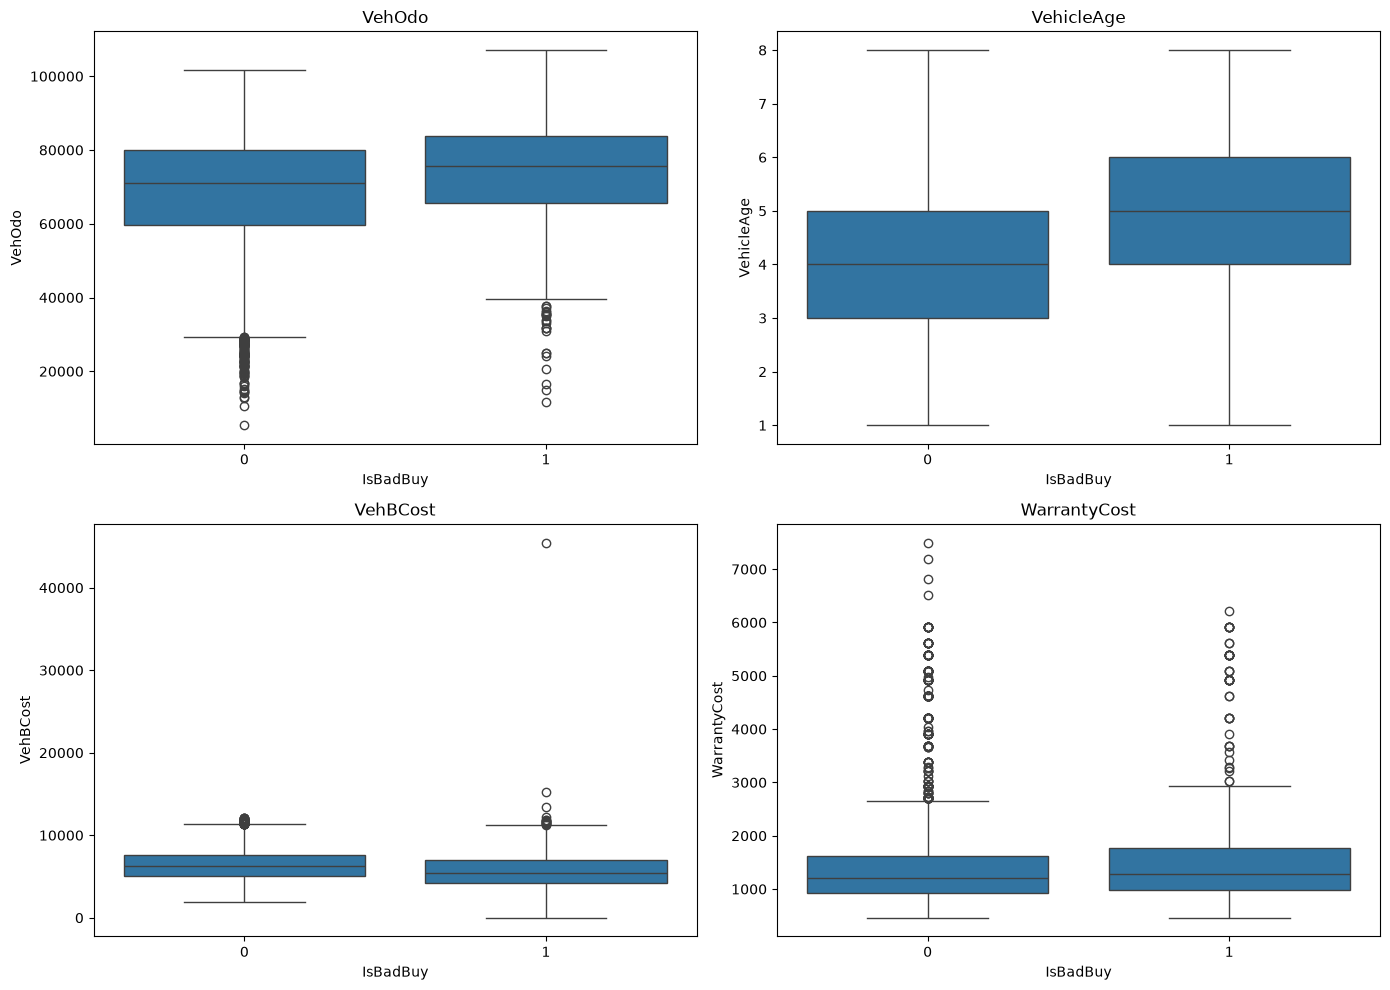

In [23]:
numeric_features = [
    "VehOdo",
    "VehicleAge",
    "VehBCost",
    "WarrantyCost"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(numeric_features, axes.flat):
    sns.boxplot(
        data=train,
        x="IsBadBuy",
        y=feature,
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("IsBadBuy")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

Распределения числовых признаков различаются для удачных и неудачных покупок:

- **VehOdo:** у неудачных покупок медианный пробег несколько выше.
- **VehicleAge:** неудачные покупки в среднем связаны с более старыми автомобилями. Медианный возраст составляет 5 лет против 4 лет.
- **VehBCost:** у неудачных покупок медианная стоимость приобретения ниже.
- **WarrantyCost:** медианное значение у неудачных покупок немного выше.

Распределения признаков частично перекрываются, поэтому ни один из них сам по себе не позволяет однозначно определить класс. Также заметно большое количество выбросов, особенно у `VehBCost` и `WarrantyCost`.

Полученные различия показывают, что числовые признаки могут быть полезны для классификации. На следующем этапе проверим взаимосвязи между ними и целевой переменной.

### 3.7. Корреляционный анализ

Построим корреляционную матрицу для числовых признаков обучающей выборки.

Анализ позволит:
- оценить линейную связь признаков с целевой переменной;
- выявить признаки с высокой взаимной корреляцией;
- проверить наличие потенциальной мультиколлинеарности.

Для расчёта используем коэффициент корреляции Пирсона.

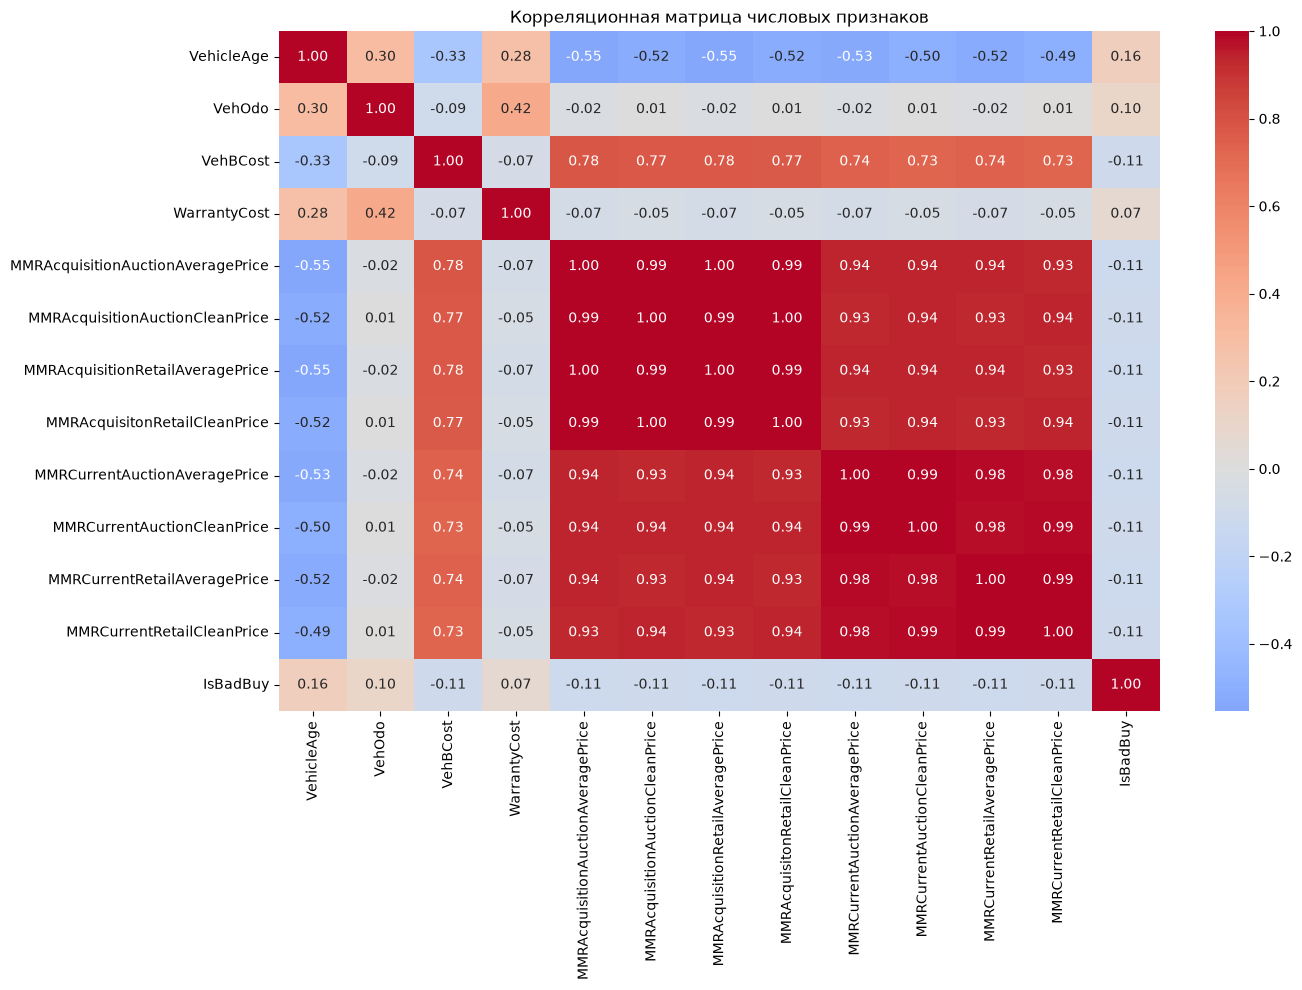

In [25]:
num_features = [
    "VehicleAge",
    "VehOdo",
    "VehBCost",
    "WarrantyCost",
    'MMRAcquisitionAuctionAveragePrice',
    'MMRAcquisitionAuctionCleanPrice',
    'MMRAcquisitionRetailAveragePrice',
    'MMRAcquisitonRetailCleanPrice',
    'MMRCurrentAuctionAveragePrice',
    'MMRCurrentAuctionCleanPrice',
    'MMRCurrentRetailAveragePrice',
    'MMRCurrentRetailCleanPrice',
    "IsBadBuy"
]

corr = train[num_features].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

1. **Связь с целевой переменной.** Наиболее заметная линейная корреляция наблюдается у `VehicleAge` (0.16), `VehBCost` (-0.11), признаков MMR (около -0.11) и `VehOdo` (0.10). При этом все значения невысокие, то есть выраженной линейной зависимости отдельных признаков от целевой переменной нет.

2. **Сильная взаимная корреляция MMR-признаков.** Показатели рыночной стоимости автомобилей имеют корреляцию между собой от 0.93 до 1.00. Это указывает на сильную избыточность информации и потенциальную мультиколлинеарность.

3. **Связь стоимости автомобиля с другими характеристиками.** `VehBCost` положительно коррелирует с показателями MMR (0.73–0.78) и отрицательно — с `VehicleAge` (-0.33).

4. **Другие зависимости.** `VehOdo` умеренно положительно коррелирует с `WarrantyCost` (0.42) и слабо — с `VehicleAge` (0.30).

Таким образом, признаки MMR содержат во многом схожую информацию. При дальнейшем построении моделей стоит учитывать возможную мультиколлинеарность. При этом низкая корреляция с целевой переменной не означает, что признак бесполезен для классификации: модель может выявлять нелинейные зависимости и взаимодействия признаков.

# 4. Preprocessing

Проанализируем количество и долю пропусков в признаках обучающей выборки. На основании результатов определим стратегию заполнения или исключения отдельных признаков.

In [26]:
missing = pd.DataFrame({
    "Пропуски": train.isna().sum(),
    "Доля, %": train.isna().mean() * 100
})

missing = missing[missing["Пропуски"] > 0]
missing = missing.sort_values("Доля, %", ascending=False)

display(missing.round(2))

,Пропуски,"Доля, %"
AUCGUART,23057,99.99
PRIMEUNIT,23057,99.99
WheelType,872,3.78
WheelTypeID,872,3.78
Trim,694,3.01
MMRCurrentAuctionCleanPrice,258,1.12
MMRCurrentAuctionAveragePrice,258,1.12
MMRCurrentRetailCleanPrice,258,1.12
MMRCurrentRetailAveragePrice,258,1.12
SubModel,8,0.03


Признаки AUCGUART и PRIMEUNIT содержат более 99% пропущенных значений в обучающей выборке. Из-за крайне малого количества заполненных наблюдений они будут исключены из дальнейшего анализа.

Также исключим WheelTypeID

Выделим целевую переменную IsBadBuy и сформируем матрицы признаков для обучающей, валидационной и тестовой выборок.

Исключим идентификатор RefId, дату PurchDate и константный признак IsOnlineSale. Дата уже была использована для хронологического разделения данных.

In [27]:
drop_features = ["AUCGUART", "PRIMEUNIT", "WheelTypeID", "RefId", "PurchDate", "IsOnlineSale"]

train = train.drop(columns=drop_features)
valid = valid.drop(columns=drop_features)
test = test.drop(columns=drop_features)

X_train = train.drop(columns=["IsBadBuy"])
y_train = train["IsBadBuy"]

X_valid = valid.drop(columns=["IsBadBuy"])
y_valid = valid["IsBadBuy"]

X_test = test.drop(columns=["IsBadBuy"])
y_test = test["IsBadBuy"]